In [1]:
using Plots
using Distributions, Random, Statistics
using LinearAlgebra, SparseArrays, JSON
using Colors
using CSV
using DataFrames

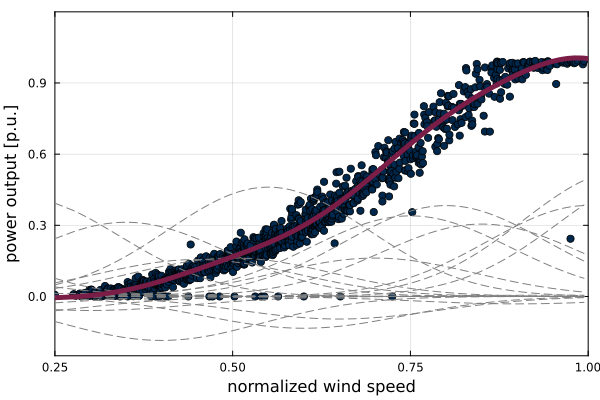

In [ ]:
# RBF-SVM for wind power curve fitting with Tikhonov regularization, wind power data example from ECE 598

purple = RGB(122/256, 30/256, 71/256)
blue   = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

dataset = JSON.parsefile("wind_power_data.json")

n = length(dataset["ActivePower"])

sort_index = sortperm(dataset["WindSpeed"])

t = Float64.(dataset["ActivePower"][sort_index])

x_raw = Float64.(dataset["WindSpeed"][sort_index])
x = x_raw ./ 10.0

# Parameters
α = 0.01          # learning rate
iter_max = 25_000 # maximum iterations
λ = 0.001         # regularization coefficient

reg_type = "l2"

c = collect(0.0:0.05:1.1)

num_centers = length(c)

γ = 5.0

# Gaussian RBF
function φ(x, j)
    return exp(-(γ * abs(x - c[j]))^2)
end


Φ = zeros(n, num_centers)

for i in 1:n
    for j in 1:num_centers
        Φ[i, j] = φ(x[i], j)
    end
end

Random.seed!(128)

w_0 = rand()

w = rand(num_centers)

# Stochastic Gradient Descent
for iteration in 1:iter_max

    # Randomly select one training sample
    i = rand(1:n)

    # RBF values for selected sample
    ϕi = Φ[i, :]

    y_hat = w_0 + dot(ϕi, w)

    # Error
    error = y_hat - t[i]

    # Intercept
    w_0 -= α * error

    # RBF weights
    for j in 1:num_centers
        w[j] -= α * error * ϕi[j]
    end

    if reg_type == "l2"

        # Do not regularize the intercept
        w .-= α * λ .* w

    elseif reg_type == "l1"

        # L1 regularization on RBF weights
        w .= sign.(w) .* max.(0, abs.(w) .- α * λ)

    end

end

function w̅(x_value)
    return w_0 + sum(w[j] * φ(x_value, j)
                     for j in 1:num_centers)
end

prediction = w_0 .+ Φ * w


plo = scatter(x,t,c = blue,frame = :box,label = false,xlabel = "normalized wind speed",ylabel = "power output [p.u.]")
plot!(plo,ylims = (-0.25, 1.2),xlims = (0.25, 1.0))

for j in 1:num_centers
    plot!(plo,x,w[j] .* Φ[:, j],c = :gray,label = false,linestyle = :dash)
end

plot!(plo,x,fill(w_0, length(x)),c = :gray,label = false,linestyle = :dash)
plot!(plo,w̅,0.25,1.0,lw = 5,c = purple,label = false)

display(plo)


In [38]:
# ---------------------------------------------------------
# Model error metrics
# ---------------------------------------------------------

errors = prediction .- t

RMSE = sqrt(mean(errors.^2))
MAE = mean(abs.(errors))

println()
println("========== MODEL PERFORMANCE ==========")
println("RMSE = ", RMSE)
println("MAE  = ", MAE)
println("=======================================")


========== MODEL PERFORMANCE ==========
RMSE = 0.058834962209225065
MAE  = 0.03543028988092969


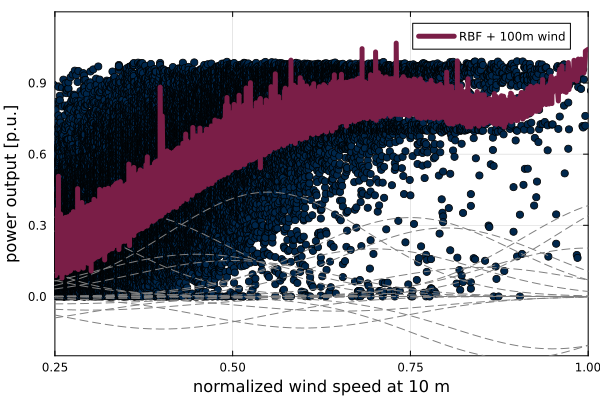

Number of observations = 43800
Intercept w_0 = -0.745694750048839
100 m wind coefficient β_100 = 0.6038687166659642


In [15]:
# RBF-SVM for wind power curve fitting with Tikhonov regularization
# Methods from example adapted for Kaggle data set
# Two parameters: wind speed 10m, wind speed 100m
# Sorted by wind speed

purple = RGB(122/256, 30/256, 71/256)
blue   = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

data = CSV.read("Location1.csv", DataFrame)

n = nrow(data)

# Sort by wind speed
sort_index = sortperm(data.windspeed_10m)

t = Float64.(data.Power[sort_index])

wind10_raw = Float64.(data.windspeed_10m[sort_index])
wind100_raw = Float64.(data.windspeed_100m[sort_index])

x = wind10_raw ./ 10.0

z = wind100_raw ./ 10.0

# ---------------------------------------------------------
# Gaussian radial basis functions
# ---------------------------------------------------------

c = collect(0.0:0.05:1.1)

num_centers = length(c)

γ = 5.0

function φ(x, j)
    return exp(-(γ * abs(x - c[j]))^2)
end

Φ = zeros(n, num_centers)

for i in 1:n
    for j in 1:num_centers
        Φ[i, j] = φ(x[i], j)
    end
end

# ---------------------------------------------------------
# Parameters
# ---------------------------------------------------------

α = 0.01
iter_max = 25_000
λ = 0.001

Random.seed!(128)

w_0 = rand()

w = rand(num_centers)

β_100 = rand()

# ---------------------------------------------------------
# Stochastic Gradient Descent
# ---------------------------------------------------------

for iteration in 1:iter_max

    # Randomly select one training sample
    i = rand(1:n)

    # RBF values for selected sample
    ϕi = Φ[i, :]

    y_hat = w_0 +
            dot(ϕi, w) +
            β_100 * z[i]

    # Error
    error = y_hat - t[i]

    w_0 -= α * error

    for j in 1:num_centers
        w[j] -= α * error * ϕi[j]
    end

    β_100 -= α * error * z[i]

    w .-= α * λ .* w

    # Regularize the additional predictor
    β_100 -= α * λ * β_100

end

# ---------------------------------------------------------
# Prediction function
# ---------------------------------------------------------

function w̅(x_value, z_value)

    return w_0 +
           sum(w[j] * φ(x_value, j)
               for j in 1:num_centers) +
           β_100 * z_value

end

prediction = zeros(n)

for i in 1:n
    prediction[i] = w̅(x[i], z[i])
end

# ---------------------------------------------------------
# Plot observations
# ---------------------------------------------------------

plo = scatter(x,t,c = blue,frame = :box,label = false,xlabel = "normalized wind speed at 10 m",ylabel = "power output [p.u.]")
plot!(plo,ylims = (-0.25, 1.2),xlims = (0.25, 1.0))

for j in 1:num_centers
    plot!(plo,x,w[j] .* Φ[:, j],c = :gray,label = false,linestyle = :dash)
end

plot!(plo,x,fill(w_0, length(x)),c = :gray,label = false,linestyle = :dash)
plot!(plo,x,prediction,lw = 5,c = purple,label = "RBF + 100m wind")

display(plo)

# ---------------------------------------------------------
# Print learned coefficients
# ---------------------------------------------------------

println("Number of observations = ", n)
println("Intercept w_0 = ", w_0)
println("100 m wind coefficient β_100 = ", β_100)


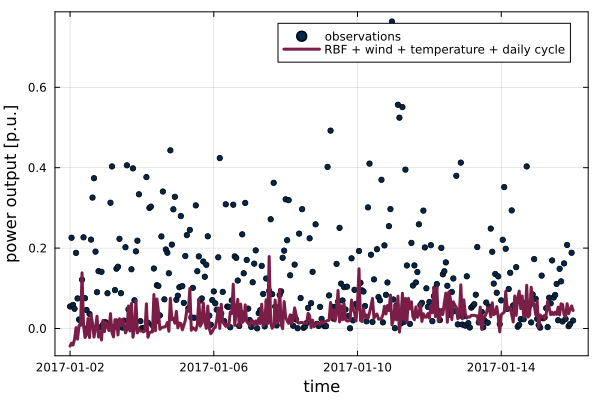

In [16]:
two_weeks = time .<= (time[1] + Day(14))
time_2wk = time[two_weeks]
t_2wk = t[two_weeks]
prediction_2wk = prediction[two_weeks]

plo = scatter(time_2wk,t_2wk,c=blue,frame=:box,label="observations",xlabel="time",ylabel="power output [p.u.]",markersize=3)
plot!(plo,time_2wk,prediction_2wk,lw=3,c=purple,label="RBF + wind + temperature + daily cycle")

display(plo)

In [40]:
# ---------------------------------------------------------
# Model error metrics
# ---------------------------------------------------------

errors = prediction .- t

RMSE = sqrt(mean(errors.^2))
MAE = mean(abs.(errors))

println()
println("========== MODEL PERFORMANCE ==========")
println("RMSE = ", RMSE)
println("MAE  = ", MAE)
println("=======================================")


========== MODEL PERFORMANCE ==========
RMSE = 0.17508859301829519
MAE  = 0.13262697396111572


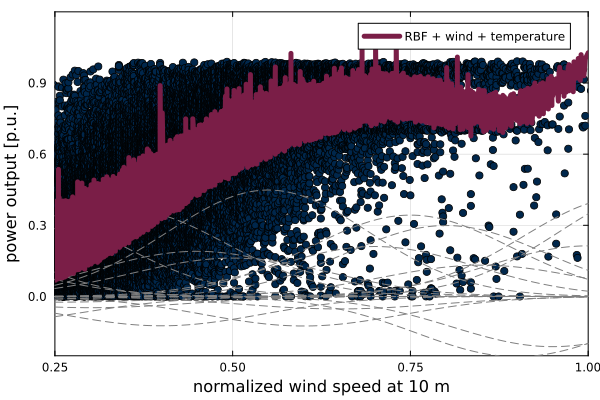


========== MODEL PARAMETERS ==========
Intercept w_0       = -0.695273937820912
100 m wind β_100    = 0.5819276080474234
Temperature β_temp  = -0.1466749448007
Temperature minimum = -14.4
Temperature maximum = 94.1


In [17]:
# RBF-SVM for wind power curve fitting with Tikhonov regularization
# Methods from example adapted for Kaggle data set
# Three parameters: wind speed 10m, wind speed 100m, temperature
# Sorted by wind speed

purple = RGB(122/256, 30/256, 71/256)
blue   = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

data = CSV.read("Location1.csv", DataFrame)

n = nrow(data)

sort_index = sortperm(data.windspeed_10m)

t = Float64.(data.Power[sort_index])

# Primary predictor
wind10_raw = Float64.(data.windspeed_10m[sort_index])

# Additional predictor 1
wind100_raw = Float64.(data.windspeed_100m[sort_index])

# Additional predictor 2
temperature_raw = Float64.(data.temperature_2m[sort_index])

x = wind10_raw ./ 10.0

z = wind100_raw ./ 10.0

# Temperature
# Min-max normalization:
# T_norm = (T - T_min) / (T_max - T_min)
T_min = minimum(temperature_raw)
T_max = maximum(temperature_raw)

temperature = (temperature_raw .- T_min) ./ (T_max - T_min)

# ---------------------------------------------------------
# Gaussian radial basis functions
# ---------------------------------------------------------

# RBF centers
c = collect(0.0:0.05:1.1)

# Number of RBFs
num_centers = length(c)

# RBF scale
γ = 5.0

# RBF definition
function φ(x, j)
    return exp(-(γ * abs(x - c[j]))^2)
end

Φ = zeros(n, num_centers)

for i in 1:n
    for j in 1:num_centers
        Φ[i, j] = φ(x[i], j)
    end
end

# ---------------------------------------------------------
# Parameters
# ---------------------------------------------------------

α = 0.01
iter_max = 25_000
λ = 0.001

Random.seed!(128)

# Intercept
w_0 = rand()

# RBF weights
w = rand(num_centers)

# Coefficient for windspeed_100m
β_100 = rand()

# Coefficient for temperature
β_temp = rand()

# ---------------------------------------------------------
# Stochastic Gradient Descent
# ---------------------------------------------------------

for iteration in 1:iter_max

    # Randomly select one training sample
    i = rand(1:n)

    # RBF values for selected sample
    ϕi = Φ[i, :]

    y_hat = w_0 +
            dot(ϕi, w) +
            β_100 * z[i] +
            β_temp * temperature[i]

    error = y_hat - t[i]

    w_0 -= α * error

    for j in 1:num_centers
        w[j] -= α * error * ϕi[j]
    end

    β_100 -= α * error * z[i]
    β_temp -= α * error * temperature[i]

    w .-= α * λ .* w

    # Regularize additional predictors
    β_100  -= α * λ * β_100
    β_temp -= α * λ * β_temp

end

# ---------------------------------------------------------
# Prediction function
# ---------------------------------------------------------

function w̅(x_value, z_value, temp_value)

    return w_0 +
           sum(w[j] * φ(x_value, j)
               for j in 1:num_centers) +
           β_100 * z_value +
           β_temp * temp_value

end


prediction = zeros(n)

for i in 1:n
    prediction[i] = w̅(x[i],z[i],temperature[i])
end

# ---------------------------------------------------------
# Plot observations
# ---------------------------------------------------------

plo = scatter(x,t,c = blue,frame = :box,label = false,xlabel = "normalized wind speed at 10 m",ylabel = "power output [p.u.]")
plot!(plo,ylims = (-0.25, 1.2),xlims = (0.25, 1.0))

for j in 1:num_centers
    plot!(plo,x,w[j] .* Φ[:, j],c = :gray,label = false,linestyle = :dash)
end

plot!(plo,x,fill(w_0, length(x)),c = :gray,label = false,linestyle = :dash)
plot!(plo,x,prediction,lw = 5,c = purple,label = "RBF + wind + temperature")

display(plo)

# ---------------------------------------------------------
# Print learned coefficients
# ---------------------------------------------------------

println()
println("========== MODEL PARAMETERS ==========")
println("Intercept w_0       = ", w_0)
println("100 m wind β_100    = ", β_100)
println("Temperature β_temp  = ", β_temp)
println("Temperature minimum = ", T_min)
println("Temperature maximum = ", T_max)
println("=======================================")


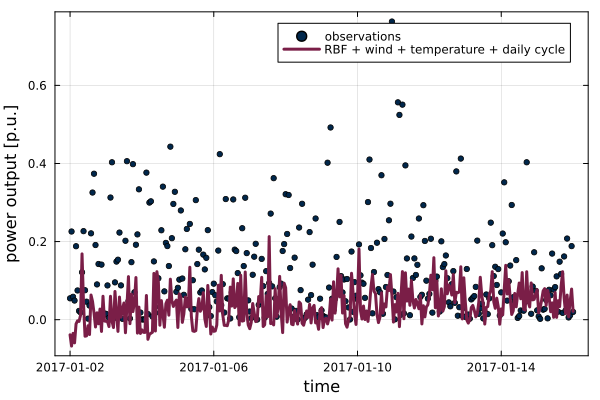

In [18]:
two_weeks = time .<= (time[1] + Day(14))
time_2wk = time[two_weeks]
t_2wk = t[two_weeks]
prediction_2wk = prediction[two_weeks]

plo = scatter(time_2wk,t_2wk,c=blue,frame=:box,label="observations",xlabel="time",ylabel="power output [p.u.]",markersize=3)
plot!(plo,time_2wk,prediction_2wk,lw=3,c=purple,label="RBF + wind + temperature + daily cycle")

display(plo)

In [12]:
# RBF-SVM for wind power curve fitting with Tikhonov regularization
# Methods from example adapted for Kaggle data set
# Three parameters: wind speed 10m, wind speed 100m, temperature
# Sorted by time

purple = RGB(122/256, 30/256, 71/256)
blue   = RGB(0/256, 39/256, 76/256)
mygreen = RGB(83/256, 165/256, 132/256)

data = CSV.read("Location1.csv", DataFrame)

n = nrow(data)

data.Time = DateTime.(data.Time)
sort_index = sortperm(data.Time)

t = Float64.(data.Power[sort_index])

# Wind speed at 10 m
wind10_raw = Float64.(data.windspeed_10m[sort_index])

# Wind speed at 100 m
wind100_raw = Float64.(data.windspeed_100m[sort_index])

# Temperature at 2 m
temperature_raw = Float64.(data.temperature_2m[sort_index])

# Time
time = data.Time[sort_index]

# 10 m wind speed
x = wind10_raw ./ 10.0

# 100 m wind speed
z = wind100_raw ./ 10.0

# Normalize temperature
T_min = minimum(temperature_raw)
T_max = maximum(temperature_raw)

temperature = (temperature_raw .- T_min) ./ (T_max - T_min)

hour = Float64.(Dates.hour.(time))

hour_sin = sin.(2π .* hour ./ 24.0)

hour_cos = cos.(2π .* hour ./ 24.0)

# ---------------------------------------------------------
# Gaussian radial basis functions
# ---------------------------------------------------------

c = collect(0.0:0.05:1.1)

num_centers = length(c)

γ = 5.0

function φ(x, j)
    return exp(-(γ * abs(x - c[j]))^2)
end


Φ = zeros(n, num_centers)

for i in 1:n
    for j in 1:num_centers
        Φ[i, j] = φ(x[i], j)
    end
end

# ---------------------------------------------------------
# Parameters
# ---------------------------------------------------------

α = 0.01
iter_max = 25_000
λ = 0.001

Random.seed!(128)

# Intercept
w_0 = rand()

# RBF weights
w = rand(num_centers)

# 100 m wind coefficient
β_100 = rand()

# Temperature coefficient
β_temp = rand()

# Daily periodicity coefficients
β_hour_sin = rand()
β_hour_cos = rand()

# ---------------------------------------------------------
# Stochastic Gradient Descent
# ---------------------------------------------------------

for iteration in 1:iter_max

    # Randomly select one observation
    i = rand(1:n)

    # RBF values for this observation
    ϕi = Φ[i, :]

    y_hat =
        w_0 +
        dot(ϕi, w) +
        β_100 * z[i] +
        β_temp * temperature[i] +
        β_hour_sin * hour_sin[i] +
        β_hour_cos * hour_cos[i]

    error = y_hat - t[i]

    w_0 -= α * error
    
    for j in 1:num_centers
        w[j] -= α * error * ϕi[j]
    end

    β_100 -= α * error * z[i]
    β_temp -= α * error * temperature[i]
    β_hour_sin -= α * error * hour_sin[i]
    β_hour_cos -= α * error * hour_cos[i]

    # Intercept is NOT regularized
    w .-= α * λ .* w

    # Additional predictor coefficients are regularized
    β_100 -= α * λ * β_100
    β_temp -= α * λ * β_temp
    β_hour_sin -= α * λ * β_hour_sin
    β_hour_cos -= α * λ * β_hour_cos

end

# ---------------------------------------------------------
# Prediction function
# ---------------------------------------------------------

function w̅(x_value,
    z_value,
    temp_value,
    hour_sin_value,
    hour_cos_value
)

    return (
        w_0 +
        sum(
            w[j] * φ(x_value, j)
            for j in 1:num_centers
        ) +
        β_100 * z_value +
        β_temp * temp_value +
        β_hour_sin * hour_sin_value +
        β_hour_cos * hour_cos_value
    )

end

# ---------------------------------------------------------
# Predictions at observed data points
# ---------------------------------------------------------

prediction = zeros(n)

for i in 1:n
    prediction[i] = w̅(x[i],z[i],temperature[i],hour_sin[i],hour_cos[i])
end


# ---------------------------------------------------------
# Print learned coefficients
# ---------------------------------------------------------

println()
println("========== MODEL PARAMETERS ==========")
println("Intercept w_0          = ", w_0)
println("100 m wind β_100       = ", β_100)
println("Temperature β_temp     = ", β_temp)
println("Hour sine β_hour_sin   = ", β_hour_sin)
println("Hour cosine β_hour_cos = ", β_hour_cos)
println("Temperature minimum    = ", T_min)
println("Temperature maximum    = ", T_max)
println("=======================================")



========== MODEL PARAMETERS ==========
Intercept w_0          = -0.6429327714090519
100 m wind β_100       = 0.45419058437118837
Temperature β_temp     = -0.15365914526144892
Hour sine β_hour_sin   = 0.023345022370849736
Hour cosine β_hour_cos = 0.003842855014671838
Temperature minimum    = -14.4
Temperature maximum    = 94.1


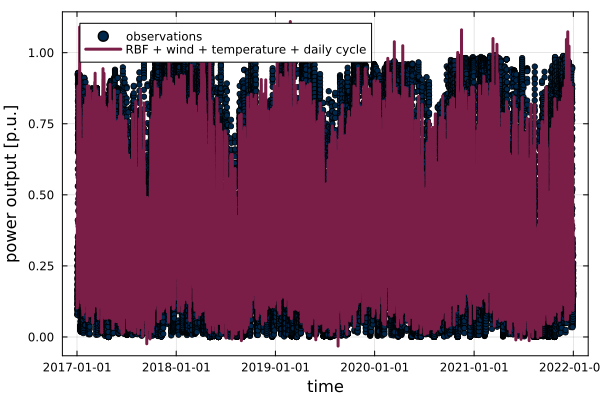

In [33]:
# Plot observations versus time
plo = scatter(time,t,c = blue,frame = :box,label = "observations",xlabel = "time",ylabel = "power output [p.u.]",markersize = 3)

# Plot model prediction versus time
plot!(plo,time,prediction,lw = 3,c = purple,label = "RBF + wind + temperature + daily cycle")

display(plo)

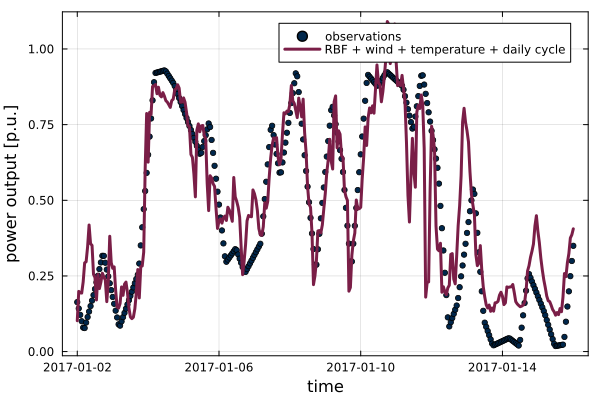

In [13]:
two_weeks = time .<= (time[1] + Day(14))
time_2wk = time[two_weeks]
t_2wk = t[two_weeks]
prediction_2wk = prediction[two_weeks]

plo = scatter(time_2wk,t_2wk,c=blue,frame=:box,label="observations",xlabel="time",ylabel="power output [p.u.]",markersize=3)
plot!(plo,time_2wk,prediction_2wk,lw=3,c=purple,label="RBF + wind + temperature + daily cycle")

display(plo)

In [ ]:
errors = prediction .- t

RMSE = sqrt(mean(errors.^2))
MAE = mean(abs.(errors))

println()
println("========== MODEL PERFORMANCE ==========")
println("RMSE = ", RMSE)
println("MAE  = ", MAE)
println("=======================================")


========== MODEL PERFORMANCE ==========
RMSE = 0.17396307963717045
MAE  = 0.13255640701674934


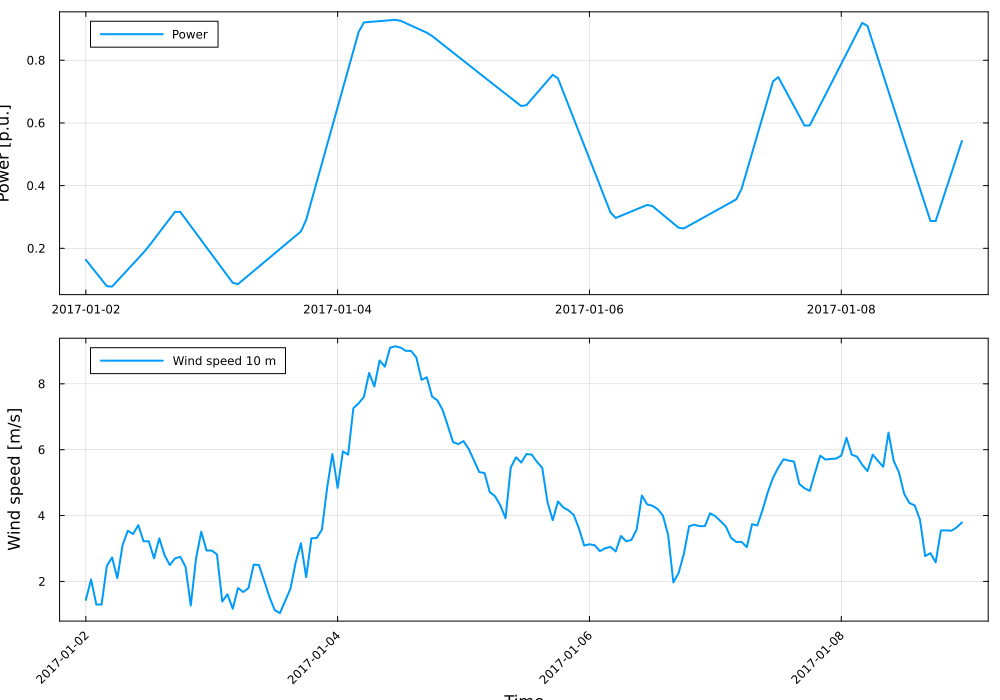

In [10]:
n_week = min(168, nrow(data))

time_week = data.Time[1:n_week]
power_week = Float64.(data.Power[1:n_week])
wind10_week = Float64.(data.windspeed_10m[1:n_week])

p1 = plot(time_week, power_week, lw=2, label="Power", xlabel="", ylabel="Power [p.u.]", frame=:box, legend=:topleft)
p2 = plot(time_week, wind10_week, lw=2, label="Wind speed 10 m", xlabel="Time", ylabel="Wind speed [m/s]", xrotation=45, frame=:box, legend=:topleft)

display(plot(p1, p2, layout=(2,1), size=(1000,700)))